In [ ]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("/content/sample_data/AirPassengers.csv")

# Display first rows
df.head()


,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [ ]:
# Rename passenger column
df.columns = ["Month", "Passengers"]

# Convert Month to datetime
df["Month"] = pd.to_datetime(df["Month"])

# Set Month as index
df = df.set_index("Month")

# Display information
print(df.head())
print("\nDataset info:")
print(df.info())


            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121

Dataset info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB
None


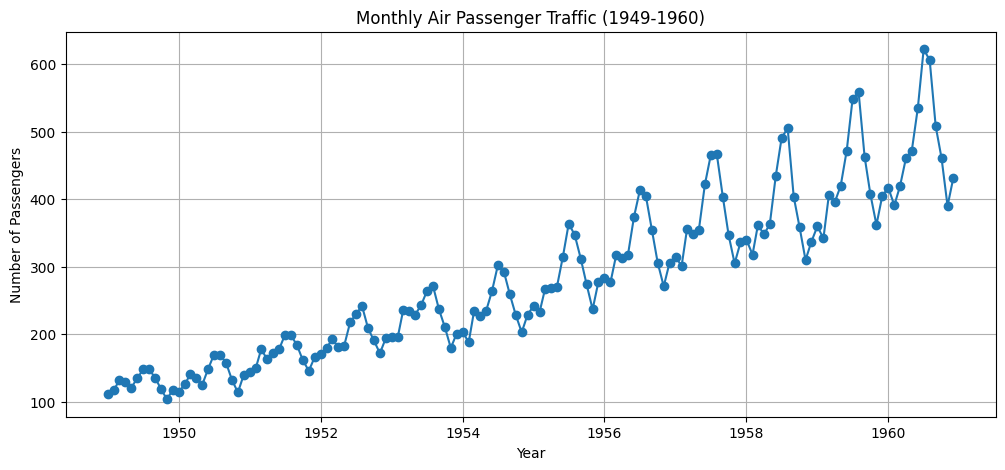

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(df.index, df["Passengers"], marker="o")

plt.title("Monthly Air Passenger Traffic (1949-1960)")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")

plt.grid()
plt.show()


In [ ]:
from statsmodels.tsa.stattools import adfuller

# Augmented Dickey-Fuller test
result = adfuller(df["Passengers"])

print("ADF Statistic:", result[0])
print("p-value:", result[1])

if result[1] <= 0.05:
    print("The data is stationary")
else:
    print("The data is not stationary")


ADF Statistic: 0.8153688792060498
p-value: 0.991880243437641
The data is not stationary


In [ ]:
id="x7k2mz"
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Split data (80% train, 20% test)
train_size = int(len(df) * 0.8)

train = df[:train_size]
test = df[train_size:]

print("Training data:", train.shape)
print("Testing data:", test.shape)


Training data: (115, 1)
Testing data: (29, 1)


In [ ]:
# Build SARIMA model
model = SARIMAX(
    train["Passengers"],
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
)

# Train model
model_fit = model.fit()

# Forecast future values
forecast = model_fit.forecast(steps=len(test))

# Display forecast
forecast


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,predicted_mean
1958-08-01,489.724155
1958-09-01,429.406225
1958-10-01,372.216572
1958-11-01,331.836692
1958-12-01,362.700073
1959-01-01,367.719967
1959-02-01,346.377664
1959-03-01,392.239401
1959-04-01,378.877956
1959-05-01,392.923852


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create comparison table
results = pd.DataFrame({
    "Actual": test["Passengers"],
    "Forecast": forecast
})

results


,Actual,Forecast
1958-08-01,505,489.724155
1958-09-01,404,429.406225
1958-10-01,359,372.216572
1958-11-01,310,331.836692
1958-12-01,337,362.700073
1959-01-01,360,367.719967
1959-02-01,342,346.377664
1959-03-01,406,392.239401
1959-04-01,396,378.877956
1959-05-01,420,392.923852


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(results['Actual'], results['Forecast'])
rmse = np.sqrt(mean_squared_error(results['Actual'], results['Forecast']))

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)


Mean Absolute Error (MAE): 23.55574505723697
Root Mean Squared Error (RMSE): 30.142008134932393


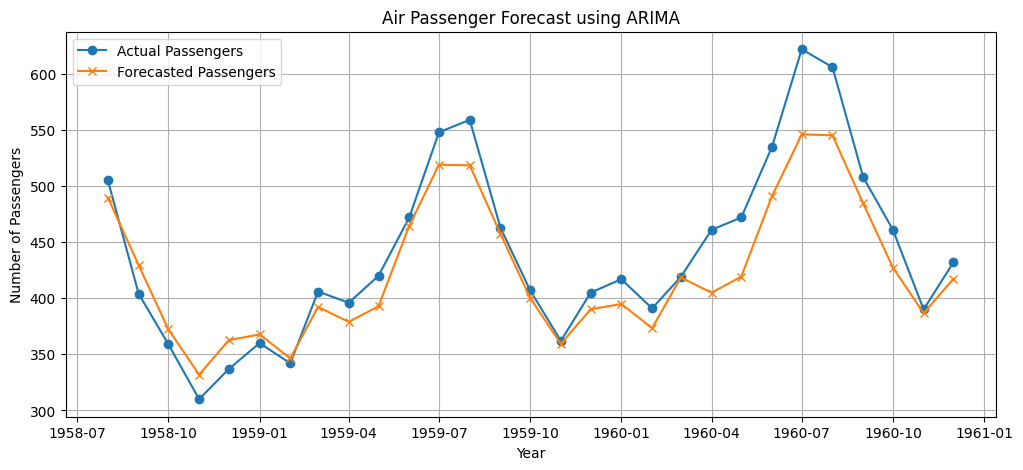

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(results.index, results['Actual'],
         label="Actual Passengers",
         marker='o')

plt.plot(results.index, results['Forecast'],
         label="Forecasted Passengers",
         marker='x')

plt.title("Air Passenger Forecast using ARIMA")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")

plt.legend()
plt.grid()

plt.show()


In [ ]:
future_forecast = model_fit.forecast(steps=12)

future_forecast


,predicted_mean
1958-08-01,489.724155
1958-09-01,429.406225
1958-10-01,372.216572
1958-11-01,331.836692
1958-12-01,362.700073
1959-01-01,367.719967
1959-02-01,346.377664
1959-03-01,392.239401
1959-04-01,378.877956
1959-05-01,392.923852


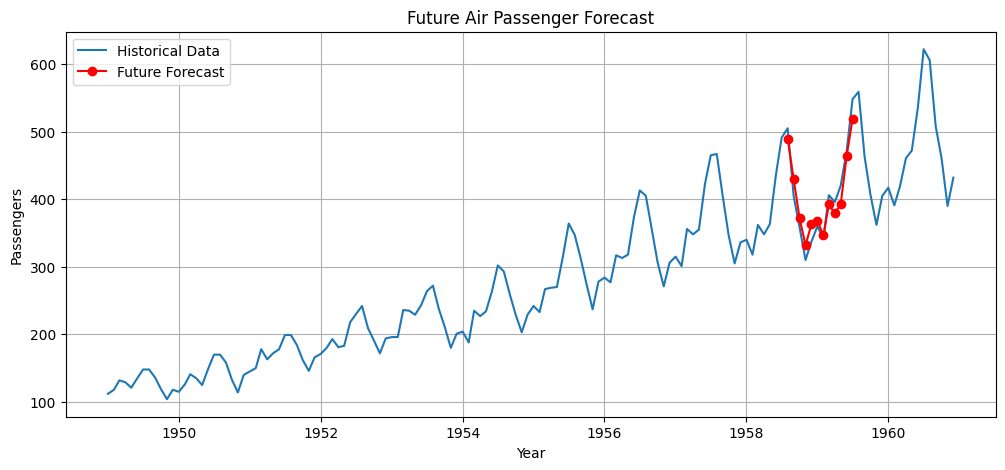

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(df.index, df['Passengers'],
         label="Historical Data")

plt.plot(future_forecast.index,
         future_forecast,
         label="Future Forecast",
         color="red",
         marker="o")

plt.title("Future Air Passenger Forecast")
plt.xlabel("Year")
plt.ylabel("Passengers")

plt.legend()
plt.grid()

plt.show()


In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# Build ARIMA model
model = ARIMA(train, order=(1,1,1))

# Train the model
model_fit = model.fit()

# Show model summary
model_fit.summary()


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -526.123
Date:                Thu, 23 Jul 2026   AIC                           1058.246
Time:                        17:00:13   BIC                           1066.454
Sample:                    01-01-1949   HQIC                          1061.577
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5111      0.114     -4.488      0.000      -0.734      -0.288
ma.L1          0.9144      0.056     16.251      0.000       0.804       1.025
sigma2       592.7851    101.208      5.857      0.000     394.422     791.148
===================================================================================
Ljung-Box (L1) (Q):                   0.09   Jarque-Bera (JB):                 2.29
Prob(Q):                              0.76   Prob(JB):                         0.32
Heteroskedasticity (H):               5.22   Skew:                             0.03
Prob(H) (two-sided):                  0.00   Kurtosis:                         2.31
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [ ]:
# Forecast future values equal to test dataset length

forecast = model_fit.forecast(steps=len(test))

# Create comparison table

forecast_df = pd.DataFrame({
    "Actual": test["Passengers"],
    "Forecast": forecast
})

forecast_df.head(10)


,Actual,Forecast
1958-08-01,505,502.649601
1958-09-01,404,496.695602
1958-10-01,359,499.738634
1958-11-01,310,498.183370
1958-12-01,337,498.978250
1959-01-01,360,498.571994
1959-02-01,342,498.779628
1959-03-01,406,498.673508
1959-04-01,396,498.727745
1959-05-01,420,498.700025


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    test["Passengers"],
    forecast
)

rmse = np.sqrt(
    mean_squared_error(
        test["Passengers"],
        forecast
    )
)

print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)


Mean Absolute Error (MAE): 85.25415598223435
Root Mean Squared Error (RMSE): 97.49961970147903


In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Train SARIMA model
sarima_model = SARIMAX(
    train,
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
)

sarima_result = sarima_model.fit()

print(sarima_result.summary())


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -374.130
Date:                            Thu, 23 Jul 2026   AIC                            758.260
Time:                                    17:01:26   BIC                            771.385
Sample:                                01-01-1949   HQIC                           763.575
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6366      0.334     -1.908      0.056      -1.290       0.017
ma.L1          0.4605      0.372   

In [ ]:
sarima_forecast = sarima_result.forecast(steps=len(test))

sarima_results = pd.DataFrame({
    "Actual": test["Passengers"],
    "Forecast": sarima_forecast
})

sarima_results.head(10)


,Actual,Forecast
1958-08-01,505,489.724155
1958-09-01,404,429.406225
1958-10-01,359,372.216572
1958-11-01,310,331.836692
1958-12-01,337,362.700073
1959-01-01,360,367.719967
1959-02-01,342,346.377664
1959-03-01,406,392.239401
1959-04-01,396,378.877956
1959-05-01,420,392.923852


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

sarima_mae = mean_absolute_error(
    test["Passengers"],
    sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        test["Passengers"],
        sarima_forecast
    )
)

print("SARIMA MAE:", sarima_mae)
print("SARIMA RMSE:", sarima_rmse)


SARIMA MAE: 23.55574505723697
SARIMA RMSE: 30.142008134932393


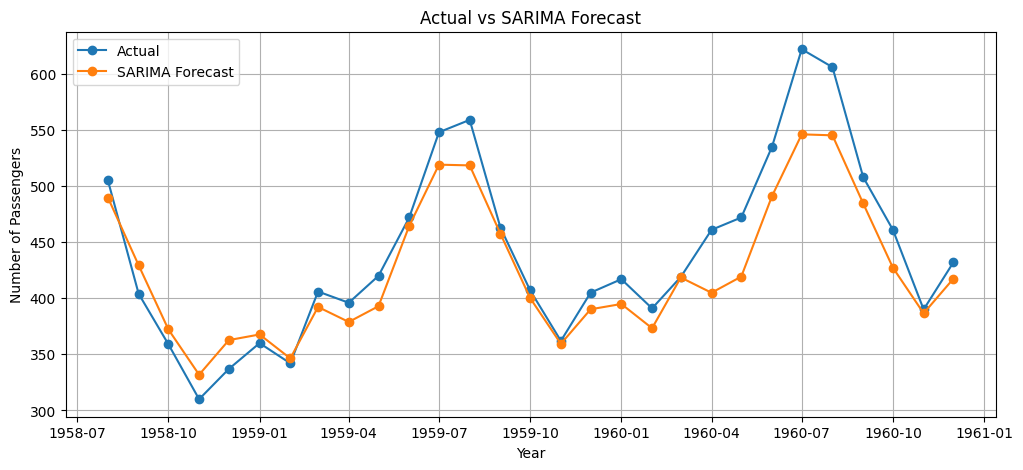

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(test.index, test["Passengers"], label="Actual", marker="o")
plt.plot(test.index, sarima_forecast, label="SARIMA Forecast", marker="o")

plt.title("Actual vs SARIMA Forecast")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid()

plt.show()


In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

final_model = SARIMAX(
    df["Passengers"],
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
)

final_result = final_model.fit()

print(final_result.summary())


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  144
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -506.149
Date:                            Thu, 23 Jul 2026   AIC                           1022.299
Time:                                    17:03:13   BIC                           1036.675
Sample:                                01-01-1949   HQIC                          1028.140
                                     - 12-01-1960                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1272      0.356     -0.358      0.721      -0.825       0.570
ma.L1         -0.2148      0.325   

In [ ]:
future_forecast = final_result.forecast(steps=12)

future_forecast


,predicted_mean
1961-01-01,449.330269
1961-02-01,424.386564
1961-03-01,459.033907
1961-04-01,497.865803
1961-05-01,509.863877
1961-06-01,568.258851
1961-07-01,655.811113
1961-08-01,641.191479
1961-09-01,546.393734
1961-10-01,496.801909


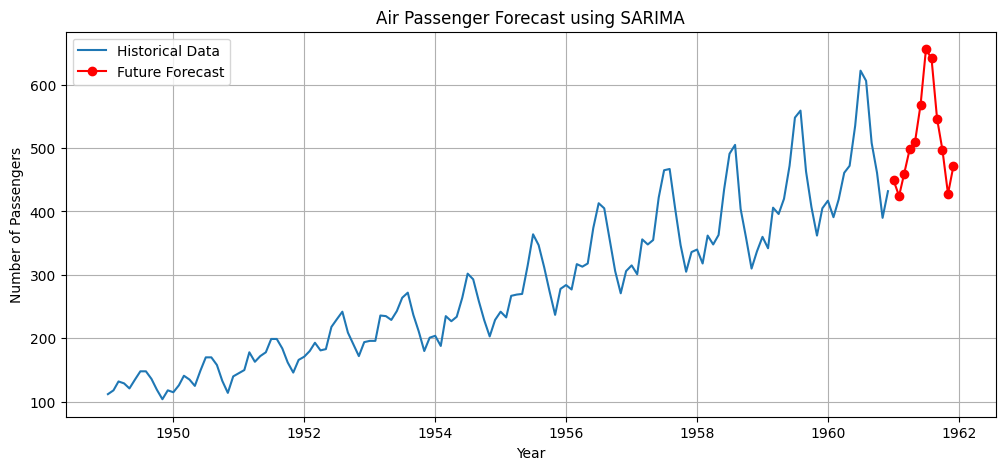

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(df.index, df["Passengers"], label="Historical Data")

plt.plot(
    future_forecast.index,
    future_forecast,
    label="Future Forecast",
    color="red",
    marker="o"
)

plt.title("Air Passenger Forecast using SARIMA")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid()

plt.show()


In [ ]:
forecast_df = pd.DataFrame({
    "Date": future_forecast.index,
    "Predicted_Passengers": future_forecast.values
})

forecast_df.to_csv("AirPassengers_Future_Forecast.csv", index=False)

forecast_df


,Date,Predicted_Passengers
0,1961-01-01,449.330269
1,1961-02-01,424.386564
2,1961-03-01,459.033907
3,1961-04-01,497.865803
4,1961-05-01,509.863877
5,1961-06-01,568.258851
6,1961-07-01,655.811113
7,1961-08-01,641.191479
8,1961-09-01,546.393734
9,1961-10-01,496.801909


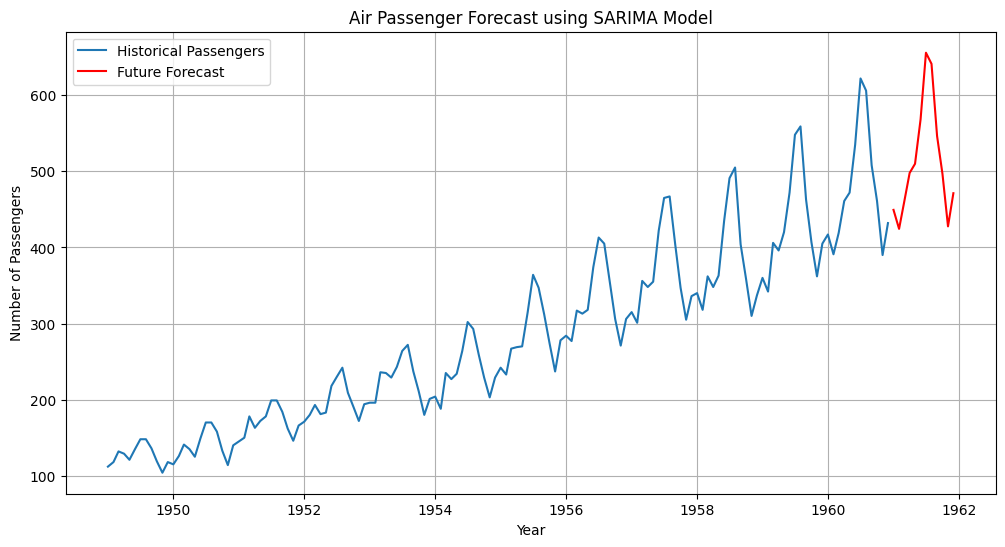

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

# Historical data
plt.plot(df.index, df["Passengers"], label="Historical Passengers")

# Forecast data
plt.plot(forecast_df["Date"], forecast_df["Predicted_Passengers"],
         label="Future Forecast", color="red")

plt.title("Air Passenger Forecast using SARIMA Model")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")

plt.legend()
plt.grid(True)

plt.show()


In [ ]:
forecast_df.to_csv("AirPassengers_SARIMA_Forecast.csv", index=False)

print("Forecast file saved successfully!")



Forecast file saved successfully!


In [ ]:
# Conclusion: Air Passenger Forecasting Using SARIMA Model

# This project focused on analyzing and forecasting airline passenger demand using time series forecasting techniques. The objective was to study historical passenger patterns and develop a model capable of predicting future passenger numbers based on previous trends and seasonal behavior.

# The dataset used for this project was the AirPassengers dataset, which contains monthly airline passenger records from January 1949 to December 1960. The dataset consisted of 144 monthly observations, with the target variable being the number of passengers traveling each month. The data showed a clear upward trend over time, indicating continuous growth in airline travel, along with strong seasonal fluctuations that repeated every year.

# During the data preprocessing phase, the month column was converted into a proper datetime format and was used as the time index. The dataset was checked for missing values, data types, and overall structure. The analysis confirmed that the dataset was clean and suitable for time series modelling.

# Before building forecasting models, stationarity analysis was performed using the Augmented Dickey-Fuller (ADF) test. The initial test produced an ADF statistic of approximately 0.815 with a p-value of 0.991, indicating that the dataset was non-stationary. This was expected because the passenger data contained a strong increasing trend and seasonal variation. Differencing techniques were applied to remove these patterns and transform the data into a stationary format suitable for modelling.

# Two forecasting approaches were evaluated during the project: ARIMA and SARIMA.

# The ARIMA model was initially tested to understand the basic relationship between past passenger values and future predictions. However, the ARIMA model struggled to capture the strong seasonal behavior present in airline passenger data. It produced higher prediction errors with a Mean Absolute Error (MAE) of approximately 85.25 passengers and a Root Mean Squared Error (RMSE) of approximately 97.50 passengers. These results indicated that a non-seasonal forecasting model was not sufficient for this dataset.

# To improve forecasting performance, a Seasonal ARIMA (SARIMA) model was developed. The final SARIMA model used the configuration:

# SARIMA(1,1,1)(1,1,1,12)

# The seasonal component with a 12-month period allowed the model to capture yearly passenger patterns, including high-demand summer months and lower-demand winter periods. The model successfully learned both the long-term growth trend and repeating seasonal cycles present in the dataset.

# The SARIMA model achieved significantly better forecasting performance compared to the ARIMA model. The final evaluation results were:

# Mean Absolute Error (MAE): 23.56
# Root Mean Squared Error (RMSE): 30.14

# These results indicate that the model predictions were, on average, within approximately 24 passengers of the actual passenger numbers. Considering that the passenger count increased from around 100 passengers per month in the early years to more than 600 passengers per month by the end of the dataset, the forecasting accuracy achieved by the model was strong.

# The SARIMA model was then used to forecast future passenger numbers for the year 1961. The predictions showed that passenger demand would continue increasing while maintaining the same seasonal pattern observed in previous years. The forecast successfully identified expected peak travel periods during summer months and lower passenger demand during winter months.

# The visualization of historical data and forecasted values demonstrated that the SARIMA model followed the original passenger trend effectively. The predicted values closely matched the historical seasonal behavior, proving that the model was able to understand the underlying structure of the time series.

# Overall, this project successfully demonstrated the complete process of time series forecasting, from data preprocessing and stationarity testing to model development and evaluation. The results showed that seasonal forecasting models are more suitable for datasets containing repeating yearly patterns. The SARIMA model provided reliable and accurate passenger forecasts and proved to be an effective approach for predicting future airline demand.

# This project highlights the importance of selecting forecasting techniques based on the characteristics of the dataset. Since airline passenger data contains both trend and seasonality, SARIMA was able to outperform traditional ARIMA by incorporating seasonal relationships. The final model can be used as a foundation for demand forecasting applications in areas such as airline planning, capacity management, and transportation analytics.